## Flight Fare Prediction

The Flight Fare Prediction project aims to build a machine learning model that accurately predicts the price of flight tickets based on multiple travel-related factors.
The dataset contains real-world flight booking information, including airline details, travel timings, route information, number of stops, flight duration, and final ticket price.

The goal of the project is to analyze these features, identify patterns influencing flight prices, and create a predictive model that can estimate fare values for new/unseen flight data.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore") #Importing Libraries

In [2]:
df=pd.read_excel("Flight_Fare.xlsx")
df #Reading the file

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


## Basic Checks

In [3]:
df.shape

(10683, 11)

In [4]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [5]:
df.tail()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648
10682,Air India,9/05/2019,Delhi,Cochin,DEL → GOI → BOM → COK,10:55,19:15,8h 20m,2 stops,No info,11753


In [6]:
df.isnull().sum() #checking null values

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [7]:
df.duplicated().sum() #checking dupicate values

220

In [8]:
df.info() #getting inference about the column types

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Airline          10683 non-null  object
 1   Date_of_Journey  10683 non-null  object
 2   Source           10683 non-null  object
 3   Destination      10683 non-null  object
 4   Route            10682 non-null  object
 5   Dep_Time         10683 non-null  object
 6   Arrival_Time     10683 non-null  object
 7   Duration         10683 non-null  object
 8   Total_Stops      10682 non-null  object
 9   Additional_Info  10683 non-null  object
 10  Price            10683 non-null  int64 
dtypes: int64(1), object(10)
memory usage: 918.2+ KB


In [9]:
df['Price'].describe() 
#The 75th percentile price is significantly higher than the median (50%), indicating some flights are much more expensive than typical fares

count    10683.000000
mean      9087.064121
std       4611.359167
min       1759.000000
25%       5277.000000
50%       8372.000000
75%      12373.000000
max      79512.000000
Name: Price, dtype: float64

## EDA

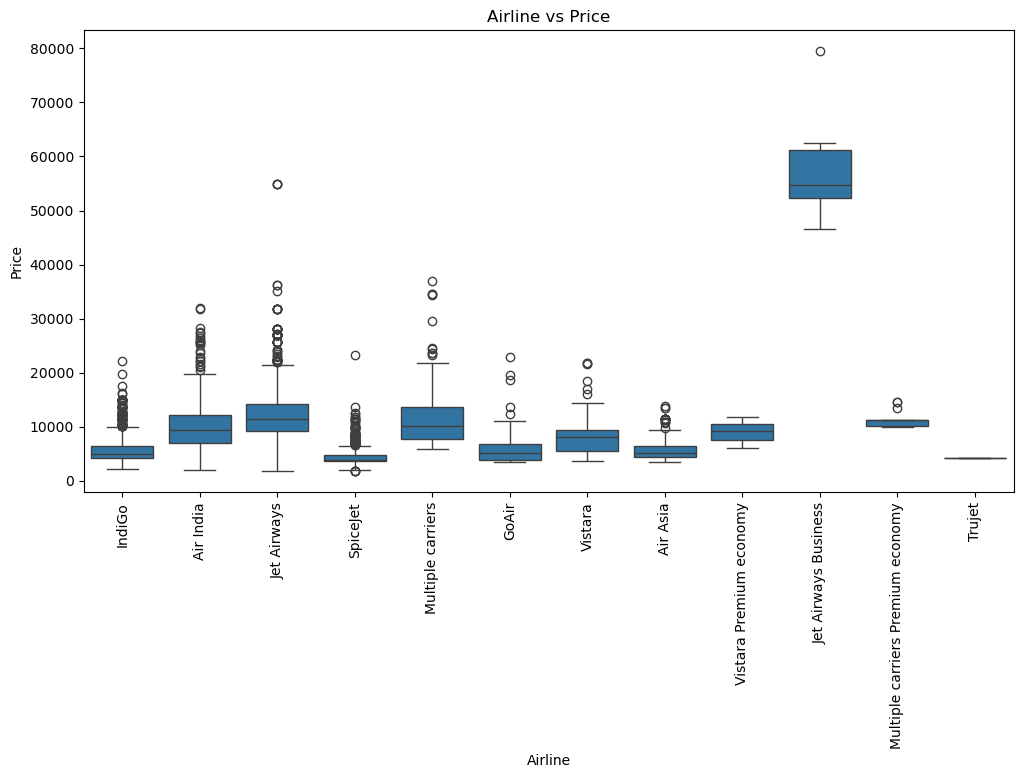

In [10]:
plt.figure(figsize=(12,6))
sns.boxplot(x='Airline', y='Price', data=df)
plt.xticks(rotation=90)
plt.title("Airline vs Price")
plt.show() 
#the boxplot indicates that Airline is an important feature influencing the final ticket price, and different carriers follow different pricing patterns.

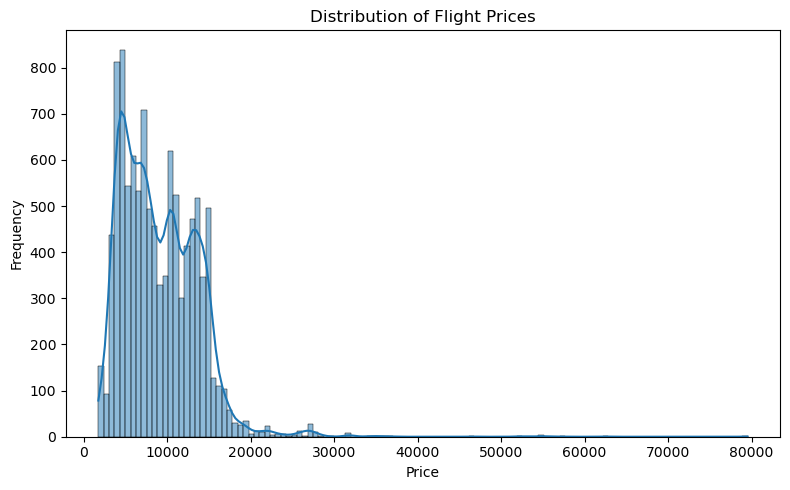

In [11]:
plt.figure(figsize=(8,5))
sns.histplot(df['Price'], kde=True)
plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()
#light prices are not normally distributed and contain significant variability, making the prediction task a regression problem with asymmetric data.

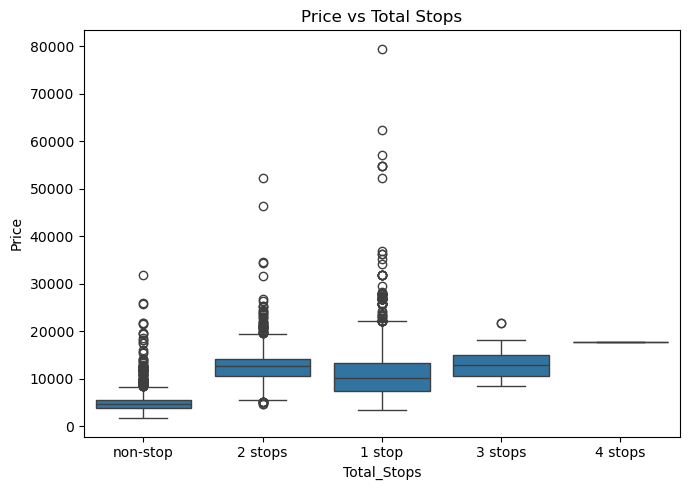

In [12]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Total_Stops', y='Price')
plt.xticks(rotation=0)
plt.title("Price vs Total Stops")
plt.tight_layout()
plt.show()
#Non-stop flights show the highest median price. 1 stop is slightly cheaper.

## Data Preprocessing and Feature Engineering

## 1.Null Values handling

In [12]:
df.isnull().sum() #handling null values

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [13]:
missing_columns=['Route','Total_Stops']

In [14]:
for i in missing_columns:
  if i=='Route':
    df[i]=df[i].fillna(df[i].mode()[0])
  elif i=='Total_Stops':
    df[i]=df[i].fillna(df[i].mode()[0]) #replacing with mode

In [15]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              0
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        0
Additional_Info    0
Price              0
dtype: int64

## 2. checking Duplicates

In [16]:
df.duplicated().sum()

220

In [17]:
df=df.drop_duplicates() 
df #handpling duplicates

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302
...,...,...,...,...,...,...,...,...,...,...,...
10678,Air Asia,9/04/2019,Kolkata,Banglore,CCU → BLR,19:55,22:25,2h 30m,non-stop,No info,4107
10679,Air India,27/04/2019,Kolkata,Banglore,CCU → BLR,20:45,23:20,2h 35m,non-stop,No info,4145
10680,Jet Airways,27/04/2019,Banglore,Delhi,BLR → DEL,08:20,11:20,3h,non-stop,No info,7229
10681,Vistara,01/03/2019,Banglore,New Delhi,BLR → DEL,11:30,14:10,2h 40m,non-stop,No info,12648


## 3. checking Outliers

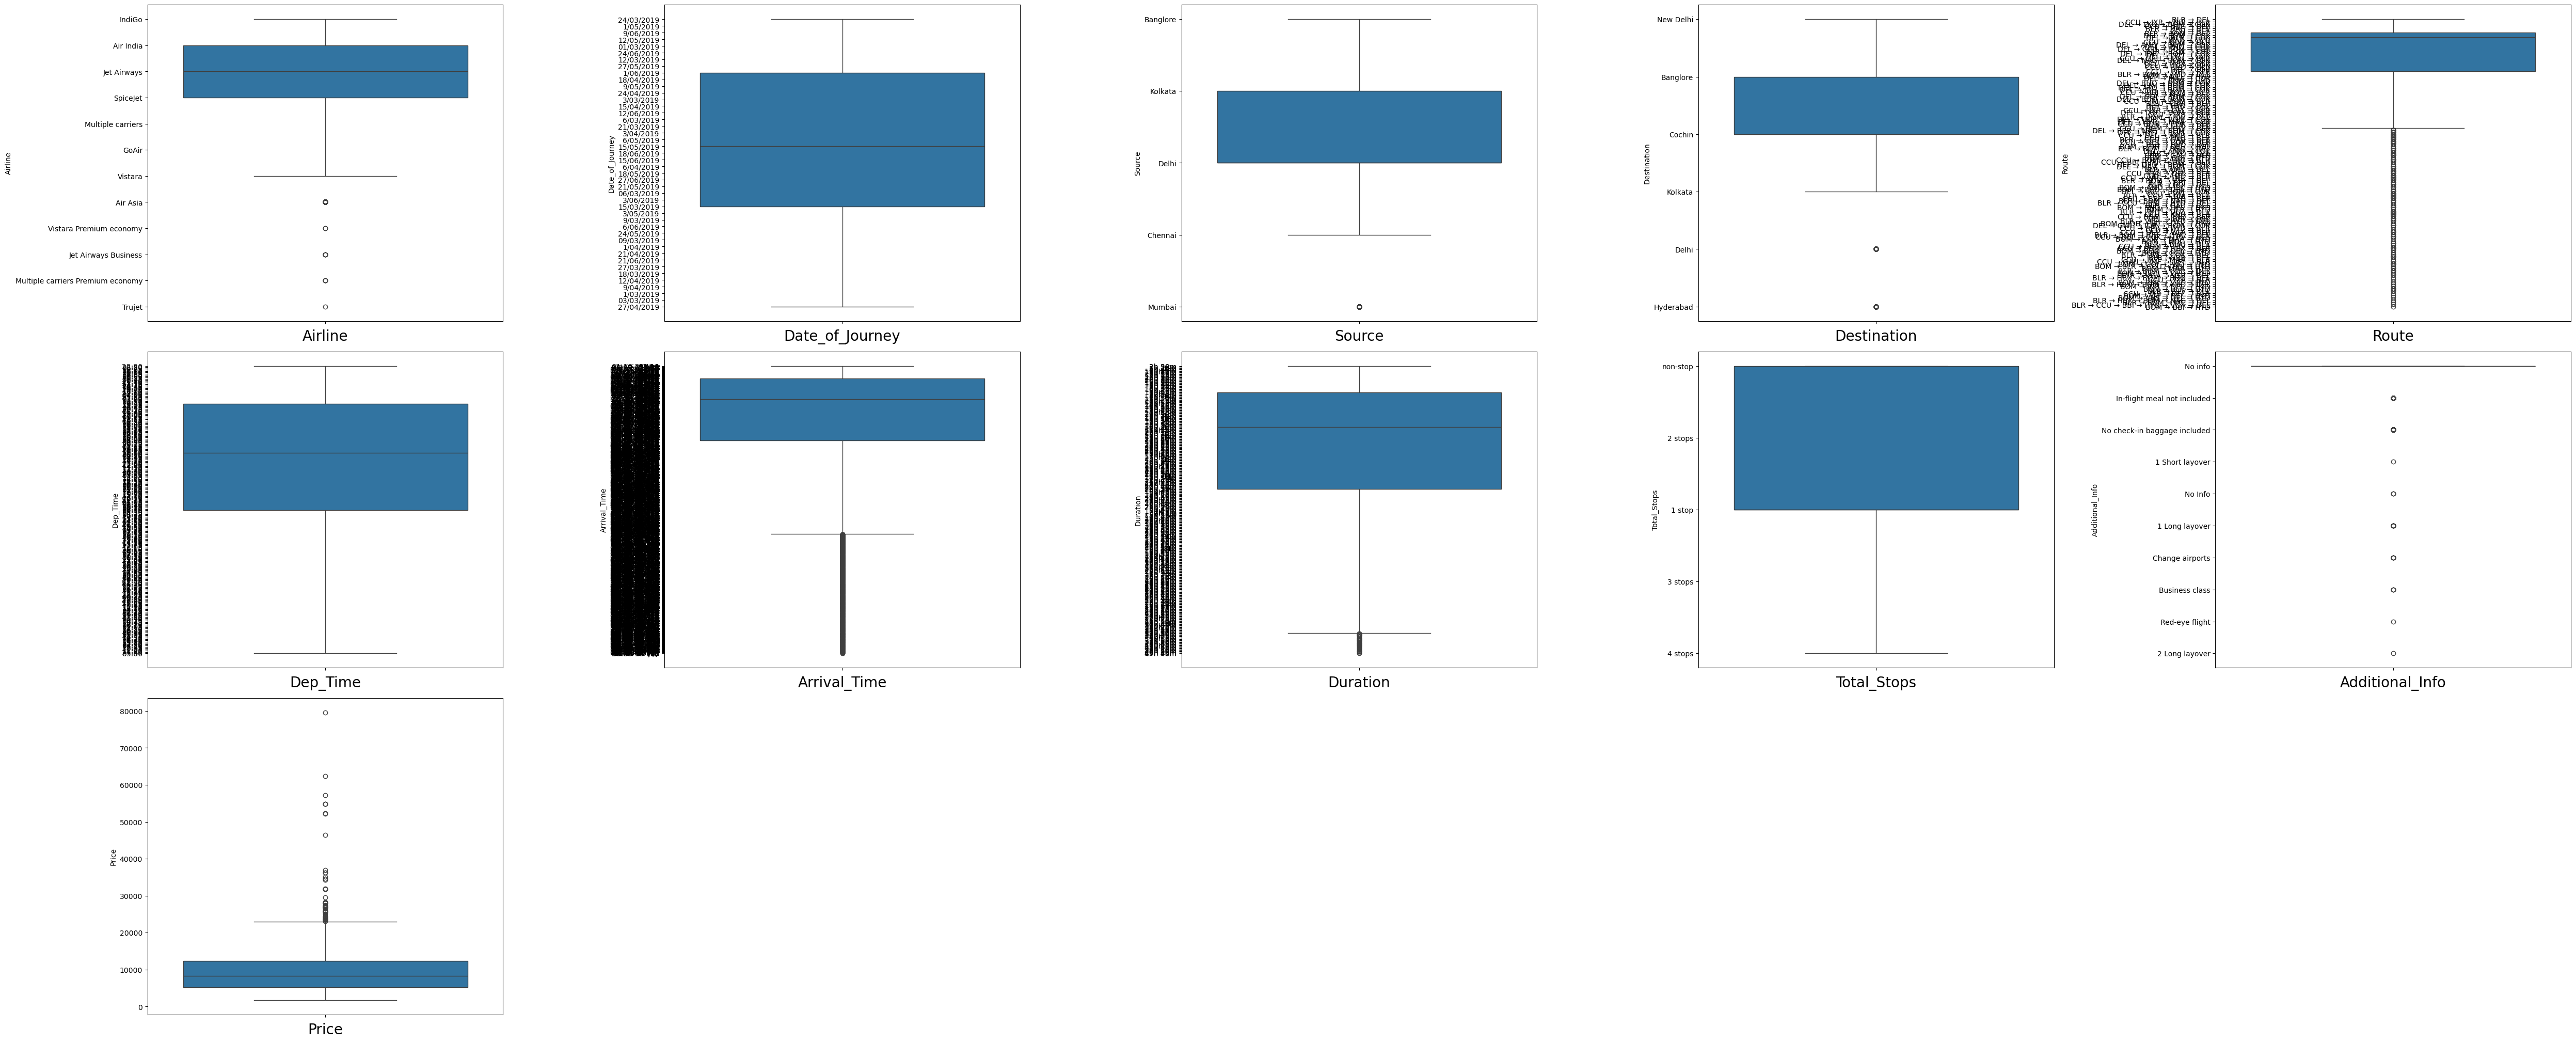

In [18]:
plt.figure(figsize=(50,40),facecolor="white")
pn=1
for i in df.columns:
  plt.subplot(6,5,pn)
  sns.boxplot(df[i])
  plt.xlabel(i,fontsize=20)
  pn=pn+1
plt.tight_layout() #checking for outliers

In [20]:
#Price Outliers:
#The boxplot shows multiple outliers on the higher end of the price range.
#These represent:
#>Last-minute bookings
#>Premium airlines
#>Business-class tickets
#>Long-duration multi-stop flights
#>These outliers are natural variations in flight data and should not be removed, because they reflect real pricing behavior.

In [21]:
#Duration Outliers:
#Long-duration flights show outliers, usually corresponding to:
#>Layovers
#>Connecting flights
#>2-stop or 3-stop flights
#These should also not be removed, because they are valid flight records.

In [19]:
#Converts the date column from string/object to datetime format.

df['Date_of_Journey'] = pd.to_datetime(df['Date_of_Journey'])

df['Journey_Day'] = df['Date_of_Journey'].dt.day
df['Journey_Month'] = df['Date_of_Journey'].dt.month
df['Journey_Year'] = df['Date_of_Journey'].dt.year


In [23]:
#Flight prices change with time of day:
>#Early morning flights (2 AM–6 AM) cheaper
>#Evening/peak hour flights more expensive
>#Instead of using the whole "HH:MM" string, we convert into numerical values.



SyntaxError: invalid syntax (1046676289.py, line 2)

In [ ]:
#Departure and arrival times are converted into numeric hour/minute values so the model can detect pricing patterns based on time slots.

In [20]:
df['Dep_hour'] = pd.to_datetime(df['Dep_Time']).dt.hour
df['Dep_min'] = pd.to_datetime(df['Dep_Time']).dt.minute

In [21]:
df['Arrival_hour'] = pd.to_datetime(df['Arrival_Time']).dt.hour
df['Arrival_min'] = pd.to_datetime(df['Arrival_Time']).dt.minute


In [22]:
#Converting Duration to Minutes

def convert_to_mins(duration):
    duration = str(duration)
    hours = 0
    minutes = 0
    if 'h' in duration:
        hours = int(duration.split('h')[0])
        if 'm' in duration:
            minutes = int(duration.split('h')[1].replace('m','').strip())
    elif 'm' in duration:
        minutes = int(duration.replace('m','').strip())
    return hours*60 + minutes

# Apply to Duration column
df['Duration_mins'] = df['Duration'].apply(convert_to_mins)




In [23]:
print(df['Duration_mins'].isnull().sum())

0


In [24]:
print(df.columns.tolist())

['Airline', 'Date_of_Journey', 'Source', 'Destination', 'Route', 'Dep_Time', 'Arrival_Time', 'Duration', 'Total_Stops', 'Additional_Info', 'Price', 'Journey_Day', 'Journey_Month', 'Journey_Year', 'Dep_hour', 'Dep_min', 'Arrival_hour', 'Arrival_min', 'Duration_mins']


In [25]:
#dropping rows invalid to durations

df.drop(['Date_of_Journey','Dep_Time','Arrival_Time','Duration','Route'], axis=1, inplace=True)


In [26]:
#By converting Total_Stops to numbers, we turn a textual ordinal feature into meaningful numeric data that models can learn from — helping prediction accuracy.
stop_map = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
}

df['Total_Stops'] = df['Total_Stops'].map(stop_map)


In [27]:
#Encoding categorical columns

from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
cat_cols = ['Airline', 'Source', 'Destination','Additional_Info']

for col in cat_cols:
    df[col] = le.fit_transform(df[col])
#Airlines, source cities, and destination cities greatly influence pricing. Encoding converts them into machine-readable format while preserving meaning.

In [28]:
df

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_mins
0,3,0,5,0,8,3897,24,3,2019,22,20,1,10,170
1,1,3,0,2,8,7662,1,5,2019,5,50,13,15,445
2,4,2,1,2,8,13882,9,6,2019,9,25,4,25,1140
3,3,3,0,1,8,6218,12,5,2019,18,5,23,30,325
4,3,0,5,1,8,13302,1,3,2019,16,50,21,35,285
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10678,0,3,0,0,8,4107,9,4,2019,19,55,22,25,150
10679,1,3,0,0,8,4145,27,4,2019,20,45,23,20,155
10680,4,0,2,0,8,7229,27,4,2019,8,20,11,20,180
10681,10,0,5,0,8,12648,1,3,2019,11,30,14,10,160


In [29]:
df['Total_Stops'].unique()

array([0, 2, 1, 3, 4], dtype=int64)

In [30]:
numeric = df.select_dtypes(include=['int64', 'float64'])
res = numeric.corr()
res[res > 0.8] #numeric columns correlation checking

,Total_Stops,Price,Duration_mins
Total_Stops,1.0,NaN,NaN
Price,NaN,1.0,NaN
Duration_mins,NaN,NaN,1.0


## Feature Selection

In [31]:
res=df.corr()
res[res>0.8] #checking for multicollinearity

,Airline,Source,Destination,Total_Stops,Additional_Info,Price,Journey_Day,Journey_Month,Journey_Year,Dep_hour,Dep_min,Arrival_hour,Arrival_min,Duration_mins
Airline,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Source,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Destination,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Total_Stops,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Additional_Info,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Journey_Day,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Journey_Month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN
Journey_Year,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dep_hour,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN


## Model Building

In [32]:
df.isnull().sum()

Airline            0
Source             0
Destination        0
Total_Stops        0
Additional_Info    0
Price              0
Journey_Day        0
Journey_Month      0
Journey_Year       0
Dep_hour           0
Dep_min            0
Arrival_hour       0
Arrival_min        0
Duration_mins      0
dtype: int64

In [33]:
df['Duration_mins'].unique()

array([ 170,  445, 1140,  325,  285,  145,  930, 1265, 1530,  470,  795,
        155,  135,  730, 1595,  270, 1355, 1380, 1235,  310,  920,  175,
        800,  910,  345,  355,  805, 1320,  330,  625,  315,  150,  375,
        715,  665,  510, 1325,  165,  720,  965, 1195,  195, 1520,  180,
        975,  905,  390, 1505,  745, 1640,  615,  630,   90,   85, 1590,
        440,  810,  300, 1145,  890,  160, 1330,  575,  600, 1280, 1125,
        740, 1080,  555, 1050,  995,  735,  450, 1440,  535,  430,  870,
       1820,  900,  765,  610,  925,  845, 1215, 1390, 1090,  960,  140,
        480, 1015,  190,  840, 1430, 1300, 1275,  650,  495,  515,  710,
       1655,  505, 1255,  290,  490, 1465, 1415, 1545, 1570, 1730, 1515,
        560,  550,  185,  690,  570, 1055,  305, 1550, 1200,  780, 1105,
       1450,  295, 1535,  380, 1120, 1165, 1760,  545,  645,  700, 1375,
       2245, 1540,  835,  520, 1410,  755, 1455,   80,  660,  675,  875,
        775,  540,  460,  705, 1495, 1025, 1795, 13

In [34]:
X = df.drop('Price', axis=1)
y = df['Price']


In [35]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [36]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
#Scaling the independent features

In [37]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import r2_score, mean_absolute_error


param_grid = {
    "n_estimators": [100, 200, 300, 400, 500],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 7, 9, 12],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9, 1],
    "reg_alpha": [0, 0.1, 0.5, 1],
    "reg_lambda": [0.5, 1, 1.5, 2]
}


xgb = XGBRegressor(random_state=42)


xgb_random = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=20,                # tries 20 combinations
    scoring="r2",
    cv=3,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

xgb_random.fit(X_train, y_train)

cv_best_params = xgb_random.best_params_
print(f"Best parameters: {cv_best_params}")



Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best parameters: {'subsample': 0.7, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


In [42]:
#Best Parameters:
#{'subsample': 0.7, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 200, 'max_depth': 9, 'learning_rate': 0.1, 'colsample_bytree': 0.6}


In [38]:
XGB_R = XGBRegressor(**cv_best_params)
XGB_R.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.6, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=9,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=None, num_parallel_tree=None, ...)

In [44]:
#By trying with all the other algorithms XGBoost has given me best accuracy

## Model Evaluation

In [39]:
from sklearn.metrics import * 

In [40]:
y_pred=XGB_R.predict(X_test)

In [41]:
r2 = r2_score(y_test, y_pred)
print("R2 Score:", r2)

R2 Score: 0.88857501745224


In [42]:
import math
mse=mean_squared_error(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
rmse=math.sqrt(mean_squared_error(y_test,y_pred))
print(mse,mae,rmse)

2324847.3527594744 712.3288634874806 1524.745012374028


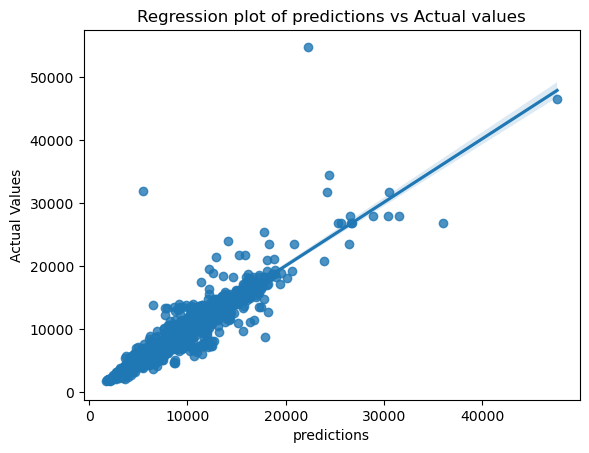

In [43]:
sns.regplot(x=y_pred,y=y_test)
plt.xlabel("predictions")
plt.ylabel("Actual Values")
plt.title("Regression plot of predictions vs Actual values")
plt.show()

## Model Evaluation with multiple models

## 1. Linear Regression

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
l_model = LinearRegression()
l_model.fit(X_train, y_train)

LinearRegression()

In [46]:
y_pred=l_model.predict(X_test)

In [47]:
r2_on_test=r2_score(y_test,y_pred)
r2_on_test

0.44333667936078613

## 2. Decision Tree Regressor

In [48]:
from sklearn.tree import DecisionTreeRegressor

In [49]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score

tree_clf = DecisionTreeRegressor(random_state=42)
params = {
    'criterion': ['squared_error', 'friedman_mse'],
    'max_depth': [3,5,7],
    'min_samples_split': [2,5],
    'min_samples_leaf': [1,2]
}


In [50]:
grid_search = GridSearchCV(tree_clf, params, cv=3, scoring='r2', n_jobs=-1)
grid_search.fit(X_train, y_train)


print("Best Parameters:", grid_search.best_params_)
print(f"Best CV R² Score: {grid_search.best_score_:.4f}")


best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)


r2 = r2_score(y_test, y_pred)
print(f"R² Score on Test Set: {r2:.4f}")

Best Parameters: {'criterion': 'squared_error', 'max_depth': 7, 'min_samples_leaf': 2, 'min_samples_split': 5}
Best CV R² Score: 0.7215
R² Score on Test Set: 0.7497


## 3. Random Forest Regressor

In [61]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Define the hyperparameter grid
random_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['squared_error', 'absolute_error']  # for regression only
}

# Initialize model
rf_rg = RandomForestRegressor(random_state=42)

# Randomized search
rf_rs = RandomizedSearchCV(
    rf_rg,
    random_grid,
    n_iter=20,         # 20 random combinations
    cv=3,
    scoring='r2',
    verbose=2,
    n_jobs=-1,
    random_state=42
)

# Fit
rf_rs.fit(X_train, y_train)

# Best model and prediction
best_rf = rf_rs.best_estimator_
y_pred = best_rf.predict(X_test)

# R2 score
r2 = r2_score(y_test, y_pred)
print("Best Parameters:", rf_rs.best_params_)
print(f"R² Score on Test Set: {r2:.4f}")



Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 15, 'criterion': 'squared_error'}
R² Score on Test Set: 0.8846


## 4. Gradient Boosting

In [54]:
from sklearn.ensemble import GradientBoostingRegressor


In [55]:
params_grid={
    'n_estimators':[50,80,100],
    'learning_rate':[0.01,0.1,0.2,0.3],
    'max_depth':[5,6,7,8],
}

In [56]:
GB=GradientBoostingRegressor()
GB_cv=GridSearchCV(GB,params_grid,cv=5,scoring='r2',verbose=2,n_jobs=-1)
GB_cv.fit(X_train,y_train)
GB_best_params=GB_cv.best_params_
print(f"Best Parameters: {GB_best_params}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Parameters: {'learning_rate': 0.3, 'max_depth': 5, 'n_estimators': 100}


In [59]:
gb_rg=GradientBoostingRegressor(**GB_best_params,random_state=42)
gb_rg.fit(X_train,y_train)
y_pred=gb_rg.predict(X_test)
print(r2_score(y_test,y_pred))

0.8780457080130813


## Report

In [ ]:
#Report
1.Missing Values
>Some columns like Route, Total_Stops, or Arrival_Time had missing values.
>Technique Used: Imputation
>Total_Stops: Filled missing values based on the most frequent value.
>Route and Duration: Extracted from related columns or filled with median/mode.
>Reason: Removing rows would reduce dataset size; imputation maintains dataset integrity.
>Inconsistent or Non-numeric Data
2.Inconsistent or Non-numeric Data
>Columns like Date_of_Journey and Duration were in string format.
>Technique Used: Feature Engineering
>Extracted day, month, hour, and minute from Date_of_Journey, Departure_Time, and Arrival_Time.
>Converted Duration into total minutes.
>Reason: Machine learning models require numeric input.
3.Categorical Variables
Columns like Airline, Source, Destination were categorical.
>Technique Used: Encoding
>Used One-Hot Encoding for nominal variables (Airline, Source, Destination).
>Used Label Encoding for ordinal features (if any).
>Reason: Models cannot handle string values; one-hot encoding avoids implying order among categories.
4.Outliers
>Price column had extreme values (very low or very high fares).
>Technique Used: Visualization & Boxplot Analysis
>Outliers were analyzed but not removed aggressively to avoid losing rare but valid pricing trends.
>Reason: Outliers can skew model training but are sometimes valid in real-world datasets.
5.Highly Skewed Data
>Features like Price and Duration were skewed.
>Technique Used: Log Transformation (optional)
>Applied log transform to stabilize variance for better model predictions.
>Reason: Helps regression models handle skewed distributions effectively.
6.Rare Categories in Airlines or Routes
>Some airlines had very few data points.
>Technique Used: Grouped rare categories under 'Other'.
>Reason: Prevents model from giving disproportionate importance to categories with very few samples.